# Figure 7B: held-out test-session classification-score histogram

In [1]:
from functools import partial

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from manuscript_analysis.contract import N_RUNS
from manuscript_analysis.figures.export import render_label_variants
from manuscript_analysis.figures.fig_utils import (
    APP_COLOUR_7B, CONTROL_COLOUR, MATCHED_ABLATION_EXPORTS, get_out_path, report_saved,
)
from manuscript_analysis.figures.score_hist import check_scores, grouped_histogram, histogram_figure

OUTPUT_DIR = get_out_path('7B')
FIGURE_NAME = '7B_test_classification_hist'
CLASS_COLOURS = {(0, 'CTRL-CO'): CONTROL_COLOUR, (1, 'AD-CO'): APP_COLOUR_7B}

scores = pd.read_csv(MATCHED_ABLATION_EXPORTS / 'session_predictions_test.csv').query("feature_set == 'all'")
assert scores['seed'].nunique() == N_RUNS and len(scores) == 275
assert not scores.duplicated(['seed', 'session']).any()
summary = (
    scores.groupby(['class_label', 'class_name'])['session']
    .agg(n_sessions='nunique', n_prediction_scores='size')
    .reset_index()
)
assert list(zip(summary['class_label'], summary['class_name'])) == list(CLASS_COLOURS)

plot_data = scores.sort_values(['class_label', 'seed', 'session'], kind='stable').reset_index(drop=True)
plot_data = plot_data[['seed', 'session', 'class_label', 'probability_ad']]
groups = [
    (plot_data.loc[plot_data['class_label'].eq(label), 'probability_ad'].to_numpy(dtype=float), colour)
    for (label, _), colour in CLASS_COLOURS.items()
]
check_scores(*(values for values, _ in groups))
display(summary)

,class_label,class_name,n_sessions,n_prediction_scores
0,0,CTRL-CO,11,100
1,1,AD-CO,25,175


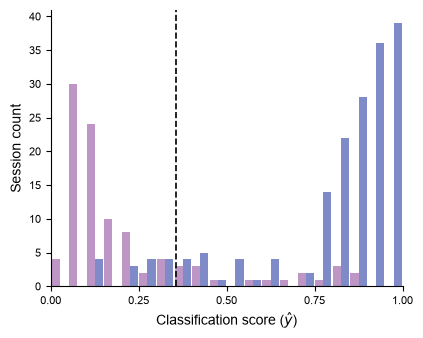

Saved output\figures\7B\7B_test_classification_hist.csv
Saved output\figures\7B\7B_test_classification_hist_with_labels.png
Saved output\figures\7B\7B_test_classification_hist_with_labels.svg
Saved output\figures\7B\7B_test_classification_hist_with_labels.pdf
Saved output\figures\7B\7B_test_classification_hist_without_labels.png
Saved output\figures\7B\7B_test_classification_hist_without_labels.svg
Saved output\figures\7B\7B_test_classification_hist_without_labels.pdf


In [2]:
def make_figure(include_labels):
    return histogram_figure([partial(grouped_histogram, groups=groups)], include_labels, figsize=(4.3, 3.45))


preview = make_figure(include_labels=True)
plt.show()

csv_path = OUTPUT_DIR / f'{FIGURE_NAME}.csv'
plot_data.to_csv(csv_path, index=False)
report_saved([csv_path, *render_label_variants(make_figure, OUTPUT_DIR, FIGURE_NAME)])